# Nepali Social-Media Comment Classification


### 4. Evaluation Protocol

### Split
- 80% training
- 20% untouched test
- stratified
- `random_state = 42`

### Primary metric
**Macro F1**



### Secondary metrics
- Accuracy
- Macro Precision
- Macro Recall
- Macro F1
- Weighted F1
- Class 3 Precision
- Class 3 Recall
- Class 3 F1
- Confusion matrix


In [1]:
import os
import re
import random
import unicodedata
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Environment initialized.")
print("Random seed:", SEED)


Environment initialized.
Random seed: 42


## 5. Upload the Workbook

In [2]:
from google.colab import files

uploaded = files.upload()

excel_files = [
    name for name in uploaded
    if name.lower().endswith((".xlsx", ".xls"))
]

WORKBOOK_PATH = excel_files[0]
xls = pd.ExcelFile(WORKBOOK_PATH)

print("Workbook:", WORKBOOK_PATH)
print("Sheets:")
for sheet in xls.sheet_names:
    print(" -", sheet)


Saving comment_classification.xlsx to comment_classification.xlsx
Workbook: comment_classification.xlsx
Sheets:
 - dharm_ds
 - nirab_ds
 - sherma_ds
 - ds_overview
 - litreture_review
 - combined_ds


## 6. Load the Three Dataset-Contributor Sheets

The project workbook uses:

- `dharm_ds`
- `nirab_ds`
- `sherma_ds`


In [5]:
SOURCE_SHEETS = ["dharm_ds", "nirab_ds", "sherma_ds"]


raw_sheets = {
    sheet: pd.read_excel(WORKBOOK_PATH, sheet_name=sheet)
    for sheet in SOURCE_SHEETS
}

for name, df in raw_sheets.items():
    print(f"\n{name}: {df.shape}")
    print("Columns:", list(df.columns))
    display(df.head(3))



dharm_ds: (3940, 6)
Columns: ['Comments', 'neutral', 'hate_speech', 'threatning', 'offensive', 'harassment']


,Comments,neutral,hate_speech,threatning,offensive,harassment
0,"Even if Harke says 2+2=4, Xetry bahun and ghan...",NaN,1.0,NaN,NaN,NaN
1,Pratiksha Neyong Limbu Ani eai rai limbu lai m...,NaN,1.0,NaN,NaN,NaN
2,Rozey Malla Thakuri ani Timaru aru jattle Rai ...,NaN,1.0,NaN,NaN,NaN



nirab_ds: (0, 6)
Columns: ['Comments', 'neutral', 'hate_speech', 'threatning', 'offensive', 'harassment']


,Comments,neutral,hate_speech,threatning,offensive,harassment



sherma_ds: (5774, 6)
Columns: ['Comment (Clean Romanized Nepali)\n', 'Neutral', 'Hate Speech', 'Threatening', 'Offensive', 'Harassment']


,Comment (Clean Romanized Nepali)\n,Neutral,Hate Speech,Threatening,Offensive,Harassment
0,gire chor kuti kuti kuti gire muge chor,0,1,0,0,0
1,jabo matra khate khate hoss ko lagi jhole hoss...,0,1,0,0,0
2,Torpey muji boli,0,0,0,1,0


## 7. Standardize Column Names



In [8]:

def standardize_source_table(df):
    df = df.copy()
    rename = {}

    for c in df.columns:
        key = str(c).strip().lower().replace("\n", " ").replace(" ", "_")

        if key in {"comment_(clean_romanized_nepali)", "comment", "comments"}:
            rename[c] = "comments"
        elif key == "threatening":
            rename[c] = "threatning"
        elif key in {"hate_speech", "offensive", "harassment", "neutral"}:
            rename[c] = key

    df = df.rename(columns=rename)

    required = [
        "comments", "neutral", "hate_speech",
        "threatning", "offensive", "harassment"
    ]

    return df[required]

standardized = {
    name: standardize_source_table(df)
    for name, df in raw_sheets.items()
}

for name, df in standardized.items():
    print(name, df.shape)


dharm_ds (3940, 6)
nirab_ds (0, 6)
sherma_ds (5774, 6)


## 8. Combine the Source Tables



In [15]:
combined = pd.concat(
    [standardized[s] for s in SOURCE_SHEETS],
    ignore_index=True
)

print("Combined shape:", combined.shape)
print("Columns:", list(combined.columns))
display(combined.head())

Combined shape: (9714, 6)
Columns: ['comments', 'neutral', 'hate_speech', 'threatning', 'offensive', 'harassment']


,comments,neutral,hate_speech,threatning,offensive,harassment
0,"Even if Harke says 2+2=4, Xetry bahun and ghan...",NaN,1.0,NaN,NaN,NaN
1,Pratiksha Neyong Limbu Ani eai rai limbu lai m...,NaN,1.0,NaN,NaN,NaN
2,Rozey Malla Thakuri ani Timaru aru jattle Rai ...,NaN,1.0,NaN,NaN,NaN
3,R*** haru,NaN,1.0,NaN,NaN,NaN
4,Madhesey ko batho talk..Marya madhesey ley 7 j...,NaN,1.0,NaN,NaN,NaN


## 9. Verify Original Labels

Each source record should have exactly one active original label.

We stop if malformed rows are found rather than silently assigning a label.


In [22]:
LABEL_COLUMNS = [
    "neutral", "hate_speech",
    "threatning", "offensive", "harassment"
]

combined["_active_original_labels"] = (
    combined[LABEL_COLUMNS]
    .fillna(0)
    .astype(float)
    .gt(0)
    .sum(axis=1)
)
display(
    combined["_active_original_labels"]
    .value_counts()
    .sort_index()
    .rename("records")
    .to_frame()
)

bad_rows = combined[combined["_active_original_labels"] != 1]

print("Rows with invalid label count:", len(bad_rows))


,records
_active_original_labels,
1,9714


Rows with invalid label count: 0


## 10. Convert Five Original Labels to Three Research Classes

Mapping:

- Neutral → Class 1
- Hate Speech + Offensive → Class 2
- Threatening + Harassment → Class 3


In [28]:
class_mapping = {
    "neutral": 1,
    "hate_speech": 2,
    "offensive": 2,
    "threatning": 3,
    "harassment": 3,
}

def assign_class(row):
    active = [
        c for c in LABEL_COLUMNS
        if float(row[c]) > 0
    ]
    return class_mapping[active[0]]

combined["class"] = combined.apply(assign_class, axis=1)
print("3-class distribution before duplicate/conflict handling:")
display(
    combined["class"]
    .value_counts()
    .sort_index()
    .rename("records")
    .to_frame()
)



3-class distribution before duplicate/conflict handling:


,records
class,
1,5902
2,3381
3,431


## 11. Duplicate and Conflict Analysis



In [31]:
def duplicate_key(text):
    text = unicodedata.normalize("NFKC", str(text))
    text = re.sub(r"\s+", " ", text).strip()
    return text

combined["dup_key"] = combined["comments"].astype(str).map(duplicate_key)

counts = combined["dup_key"].value_counts()
repeated_keys = counts[counts > 1].index

conflict_summary = (
    combined[combined["dup_key"].isin(repeated_keys)]
    .groupby("dup_key")["class"]
    .nunique()
)

conflicting_keys = conflict_summary[
    conflict_summary > 1
].index

print("Total records:", len(combined))
print("Unique normalized comments:", combined["dup_key"].nunique())
print("Repeated comment keys:", len(repeated_keys))
print("Conflicting comment keys:", len(conflicting_keys))


Total records: 9714
Unique normalized comments: 7171
Repeated comment keys: 1077
Conflicting comment keys: 38


## 12. Remove Conflicting Comments and Deduplicate


In [32]:
clean_base = combined[
    ~combined["dup_key"].isin(conflicting_keys)
].copy()

clean_base = clean_base.drop_duplicates(
    subset="dup_key",
    keep="first"
)

final_df = clean_base[
    ["comments", "class"]
].copy()

print("Final shape:", final_df.shape)
print("Missing comments:", final_df["comments"].isna().sum())
print("Unique classes:", sorted(final_df["class"].unique()))

display(
    final_df["class"]
    .value_counts()
    .sort_index()
    .rename("count")
    .to_frame()
)


Final shape: (7133, 2)
Missing comments: 0
Unique classes: [np.int64(1), np.int64(2), np.int64(3)]


,count
class,
1,3904
2,2946
3,283


## 13. Conservative Text Normalization


In [34]:
final_df["comments_clean"] = (
    final_df["comments"]
    .astype(str)
    .map(lambda x: unicodedata.normalize("NFKC", x))
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

changed = (
    final_df["comments"].astype(str)
    != final_df["comments_clean"]
).sum()

introduced_duplicates = final_df["comments_clean"].duplicated().sum()

print("Rows changed:", changed)
print("Duplicates introduced:", introduced_duplicates)

if introduced_duplicates:
    raise ValueError(
        "Normalization introduced duplicates; inspect before modeling."
    )


Rows changed: 32
Duplicates introduced: 0


## 14. Exploratory Data Analysis

We inspect:

- class distribution;
- character length;
- word count;
- URLs/emails/mentions/hashtags;
- digits and Unicode;
- repeated characters and punctuation.

This provides evidence for the preprocessing and feature decisions.


In [35]:
eda = final_df.copy()

eda["chars"] = eda["comments_clean"].str.len()
eda["words"] = eda["comments_clean"].str.split().str.len()

print("Total comments:", len(eda))
print("Empty comments:", (eda["comments_clean"].str.strip() == "").sum())

print(
    "Characters - min/mean/median/max:",
    eda["chars"].min(),
    round(eda["chars"].mean(), 2),
    eda["chars"].median(),
    eda["chars"].max()
)

print(
    "Words - min/mean/median/max:",
    eda["words"].min(),
    round(eda["words"].mean(), 2),
    eda["words"].median(),
    eda["words"].max()
)

patterns = {
    "URLs": r"https?://|www\.",
    "Emails": r"\b[^\s@]+@[^\s@]+\.[^\s@]+\b",
    "@mentions": r"@\w+",
    "hashtags": r"#\w+",
    "digits": r"\d",
    "non-ASCII": r"[^\x00-\x7F]",
    "repeated characters": r"(.)\1{2,}",
    "repeated punctuation": r"[!?.,]{2,}",
}

for name, pattern in patterns.items():
    print(
        f"{name}:",
        eda["comments_clean"].str.count(pattern).sum()
    )


Total comments: 7133
Empty comments: 0
Characters - min/mean/median/max: 2 50.22 38.0 608
Words - min/mean/median/max: 1 8.52 7.0 106
URLs: 0
Emails: 0
@mentions: 2
hashtags: 2
digits: 484
non-ASCII: 38
repeated characters: 375
repeated punctuation: 197


,comments,avg_chars,median_chars,avg_words,median_words
class,,,,,
1,3904,58.50,45.0,9.98,8.0
2,2946,37.11,26.0,6.25,4.0
3,283,72.43,58.0,12.04,9.0


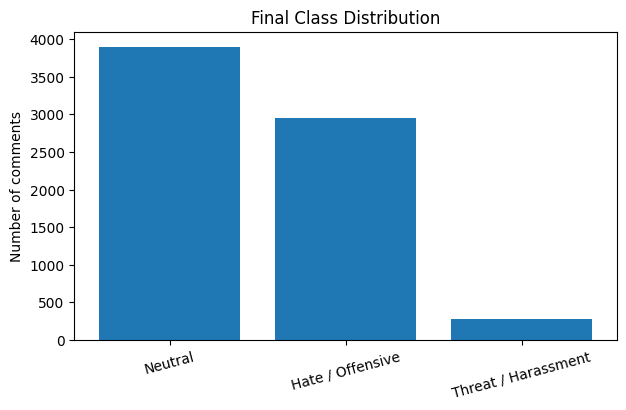

In [36]:
class_names = {
    1: "Neutral",
    2: "Hate / Offensive",
    3: "Threat / Harassment"
}

class_stats = (
    eda.groupby("class")
    .agg(
        comments=("comments_clean", "size"),
        avg_chars=("chars", "mean"),
        median_chars=("chars", "median"),
        avg_words=("words", "mean"),
        median_words=("words", "median")
    )
)

display(class_stats.round(2))

counts = final_df["class"].value_counts().sort_index()

plt.figure(figsize=(7,4))
plt.bar(
    [class_names[i] for i in counts.index],
    counts.values
)
plt.ylabel("Number of comments")
plt.title("Final Class Distribution")
plt.xticks(rotation=15)
plt.show()


## 15. Train/Test Split



In [37]:
from sklearn.model_selection import train_test_split

X = final_df["comments_clean"]
y = final_df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

print("\nTraining distribution:")
display(
    y_train.value_counts()
    .sort_index()
    .rename("count")
    .to_frame()
)

print("\nTest distribution:")
display(
    y_test.value_counts()
    .sort_index()
    .rename("count")
    .to_frame()
)


Training samples: 5706
Test samples: 1427

Training distribution:


,count
class,
1,3123
2,2357
3,226



Test distribution:


,count
class,
1,781
2,589
3,57


## 16. Common Evaluation Function



In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

def evaluate_predictions(y_true, y_pred, name):
    result = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Class 3 F1": f1_score(
            y_true, y_pred, labels=[3],
            average="macro", zero_division=0
        ),
        "Class 3 Recall": recall_score(
            y_true, y_pred, labels=[3],
            average="macro", zero_division=0
        ),
    }

    print("\n", name)
    print(pd.Series(result).drop("Model").round(4))

    print("\nClassification report:")
    print(
        classification_report(
            y_true,
            y_pred,
            labels=[1,2,3],
            target_names=[
                "Neutral",
                "Hate/Offensive",
                "Threat/Harassment"
            ],
            digits=4,
            zero_division=0
        )
    )

    print("Confusion matrix:")
    print(confusion_matrix(y_true, y_pred, labels=[1,2,3]))

    return result

results = []


# 17. Classical Model Experiments

These experiments are selected from the project's literature-guided strategy.

1. Word TF-IDF + Logistic Regression
2. Character TF-IDF + Logistic Regression
3. Word + Character TF-IDF + Logistic Regression
4. Character TF-IDF + Linear SVM
5. Character TF-IDF + Multinomial Naive Bayes
6. Word TF-IDF + Linear SVM


In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

word_vectorizer = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1,2),
    min_df=2,
    sublinear_tf=True
)

Xtr_word = word_vectorizer.fit_transform(X_train)
Xte_word = word_vectorizer.transform(X_test)

word_lr = LogisticRegression(
    C=1,
    max_iter=2000,
    class_weight="balanced",
    random_state=SEED
)

word_lr.fit(Xtr_word, y_train)
pred = word_lr.predict(Xte_word)

results.append(
    evaluate_predictions(
        y_test,
        pred,
        "Word TF-IDF + Logistic Regression"
    )
)

print("Word TF-IDF features:", Xtr_word.shape[1])



 Word TF-IDF + Logistic Regression
Accuracy           0.716188
Macro Precision    0.574868
Macro Recall       0.588595
Macro F1           0.580422
Weighted F1        0.718766
Class 3 F1         0.274194
Class 3 Recall     0.298246
dtype: object

Classification report:
                   precision    recall  f1-score   support

          Neutral     0.7901    0.7324    0.7601       781
   Hate/Offensive     0.6808    0.7351    0.7069       589
Threat/Harassment     0.2537    0.2982    0.2742        57

         accuracy                         0.7162      1427
        macro avg     0.5749    0.5886    0.5804      1427
     weighted avg     0.7235    0.7162    0.7188      1427

Confusion matrix:
[[572 181  28]
 [134 433  22]
 [ 18  22  17]]
Word TF-IDF features: 7562


## 18. Character TF-IDF + Logistic Regression



In [42]:
char_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3,5),
    min_df=2,
    sublinear_tf=True
)

Xtr_char = char_vectorizer.fit_transform(X_train)
Xte_char = char_vectorizer.transform(X_test)

char_lr = LogisticRegression(
    C=1,
    max_iter=2000,
    class_weight="balanced",
    random_state=SEED
)

char_lr.fit(Xtr_char, y_train)
pred = char_lr.predict(Xte_char)

results.append(
    evaluate_predictions(
        y_test,
        pred,
        "Character TF-IDF (3-5) + Logistic Regression"
    )
)

print("Character TF-IDF training shape:", Xtr_char.shape)
print("Character TF-IDF test shape:", Xte_char.shape)



 Character TF-IDF (3-5) + Logistic Regression
Accuracy           0.730203
Macro Precision      0.6209
Macro Recall       0.637578
Macro F1           0.628505
Weighted F1        0.731267
Class 3 F1         0.406504
Class 3 Recall     0.438596
dtype: object

Classification report:
                   precision    recall  f1-score   support

          Neutral     0.7796    0.7746    0.7771       781
   Hate/Offensive     0.7043    0.6995    0.7019       589
Threat/Harassment     0.3788    0.4386    0.4065        57

         accuracy                         0.7302      1427
        macro avg     0.6209    0.6376    0.6285      1427
     weighted avg     0.7325    0.7302    0.7313      1427

Confusion matrix:
[[605 157  19]
 [155 412  22]
 [ 16  16  25]]
Character TF-IDF training shape: (5706, 47024)
Character TF-IDF test shape: (1427, 47024)


## 19. Word + Character TF-IDF




In [41]:
from scipy.sparse import hstack

Xtr_both = hstack([Xtr_word, Xtr_char]).tocsr()
Xte_both = hstack([Xte_word, Xte_char]).tocsr()

both_lr = LogisticRegression(
    C=1,
    max_iter=2000,
    class_weight="balanced",
    random_state=SEED
)

both_lr.fit(Xtr_both, y_train)
pred = both_lr.predict(Xte_both)

results.append(
    evaluate_predictions(
        y_test,
        pred,
        "Word + Character TF-IDF + Logistic Regression"
    )
)



 Word + Character TF-IDF + Logistic Regression
Accuracy           0.737211
Macro Precision    0.615408
Macro Recall       0.606124
Macro F1           0.610361
Weighted F1        0.736657
Class 3 F1         0.333333
Class 3 Recall     0.315789
dtype: object

Classification report:
                   precision    recall  f1-score   support

          Neutral     0.7870    0.7759    0.7814       781
   Hate/Offensive     0.7063    0.7267    0.7163       589
Threat/Harassment     0.3529    0.3158    0.3333        57

         accuracy                         0.7372      1427
        macro avg     0.6154    0.6061    0.6104      1427
     weighted avg     0.7363    0.7372    0.7367      1427

Confusion matrix:
[[606 156  19]
 [147 428  14]
 [ 17  22  18]]


## 20. Character TF-IDF + Linear SVM



In [43]:
from sklearn.svm import LinearSVC

char_svm = LinearSVC(
    C=1,
    class_weight="balanced",
    random_state=SEED
)

char_svm.fit(Xtr_char, y_train)
pred = char_svm.predict(Xte_char)

results.append(
    evaluate_predictions(
        y_test,
        pred,
        "Character TF-IDF + Linear SVM"
    )
)



 Character TF-IDF + Linear SVM
Accuracy           0.742116
Macro Precision    0.661291
Macro Recall       0.579224
Macro F1           0.602996
Weighted F1        0.736321
Class 3 F1         0.313253
Class 3 Recall      0.22807
dtype: object

Classification report:
                   precision    recall  f1-score   support

          Neutral     0.7668    0.8169    0.7911       781
   Hate/Offensive     0.7170    0.6927    0.7047       589
Threat/Harassment     0.5000    0.2281    0.3133        57

         accuracy                         0.7421      1427
        macro avg     0.6613    0.5792    0.6030      1427
     weighted avg     0.7356    0.7421    0.7363      1427

Confusion matrix:
[[638 137   6]
 [174 408   7]
 [ 20  24  13]]


## 21. Character TF-IDF + Multinomial Naive Bayes


In [44]:
from sklearn.naive_bayes import MultinomialNB

char_nb = MultinomialNB()
char_nb.fit(Xtr_char, y_train)

pred = char_nb.predict(Xte_char)

results.append(
    evaluate_predictions(
        y_test,
        pred,
        "Character TF-IDF + MultinomialNB"
    )
)



 Character TF-IDF + MultinomialNB
Accuracy           0.698669
Macro Precision    0.513115
Macro Recall         0.4578
Macro F1           0.443744
Weighted F1        0.655312
Class 3 F1              0.0
Class 3 Recall          0.0
dtype: object

Classification report:
                   precision    recall  f1-score   support

          Neutral     0.6572    0.9795    0.7866       781
   Hate/Offensive     0.8821    0.3939    0.5446       589
Threat/Harassment     0.0000    0.0000    0.0000        57

         accuracy                         0.6987      1427
        macro avg     0.5131    0.4578    0.4437      1427
     weighted avg     0.7238    0.6987    0.6553      1427

Confusion matrix:
[[765  16   0]
 [357 232   0]
 [ 42  15   0]]


## 22. Word TF-IDF + Linear SVM


In [45]:
word_svm = LinearSVC(
    C=1,
    class_weight="balanced",
    random_state=SEED
)

word_svm.fit(Xtr_word, y_train)
pred = word_svm.predict(Xte_word)

results.append(
    evaluate_predictions(
        y_test,
        pred,
        "Word TF-IDF + Linear SVM"
    )
)

classical_test_results = pd.DataFrame(results)
display(
    classical_test_results
    .sort_values("Macro F1", ascending=False)
    .round(4)
)



 Word TF-IDF + Linear SVM
Accuracy           0.725298
Macro Precision    0.595617
Macro Recall       0.566064
Macro F1           0.576649
Weighted F1        0.722369
Class 3 F1         0.255319
Class 3 Recall     0.210526
dtype: object

Classification report:
                   precision    recall  f1-score   support

          Neutral     0.7743    0.7644    0.7693       781
   Hate/Offensive     0.6882    0.7233    0.7053       589
Threat/Harassment     0.3243    0.2105    0.2553        57

         accuracy                         0.7253      1427
        macro avg     0.5956    0.5661    0.5766      1427
     weighted avg     0.7208    0.7253    0.7224      1427

Confusion matrix:
[[597 171  13]
 [151 426  12]
 [ 23  22  12]]


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Class 3 F1,Class 3 Recall
1,Character TF-IDF (3-5) + Logistic Regression,0.7302,0.6209,0.6376,0.6285,0.7313,0.4065,0.4386
3,Character TF-IDF (3-5) + Logistic Regression,0.7302,0.6209,0.6376,0.6285,0.7313,0.4065,0.4386
2,Word + Character TF-IDF + Logistic Regression,0.7372,0.6154,0.6061,0.6104,0.7367,0.3333,0.3158
4,Character TF-IDF + Linear SVM,0.7421,0.6613,0.5792,0.6030,0.7363,0.3133,0.2281
0,Word TF-IDF + Logistic Regression,0.7162,0.5749,0.5886,0.5804,0.7188,0.2742,0.2982
6,Word TF-IDF + Linear SVM,0.7253,0.5956,0.5661,0.5766,0.7224,0.2553,0.2105
5,Character TF-IDF + MultinomialNB,0.6987,0.5131,0.4578,0.4437,0.6553,0.0000,0.0000


# 23. Training-Only Cross-Validation




In [49]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

char_lr_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(3,5),
            min_df=2,
            sublinear_tf=True
        )
    ),
    (
        "clf",
        LogisticRegression(
            C=1,
            max_iter=2000,
            class_weight="balanced",
            random_state=SEED
        )
    )
])

cv_scores = cross_validate(
    char_lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "macro_precision": "precision_macro",
        "macro_recall": "recall_macro",
        "macro_f1": "f1_macro"
    },
    n_jobs=-1
)

print("Mean CV Accuracy:", round(cv_scores["test_accuracy"].mean(), 4))
print("Mean CV Macro F1:", round(cv_scores["test_macro_f1"].mean(), 4))
print("CV Macro F1 std :", round(cv_scores["test_macro_f1"].std(), 4))


Mean CV Accuracy: 0.7445
Mean CV Macro F1: 0.6256
CV Macro F1 std : 0.0299


## 24. Class-Weight Comparison


In [50]:
weight_results = []

for weight in [None, "balanced"]:
    pipe = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                analyzer="char",
                ngram_range=(3,5),
                min_df=2,
                sublinear_tf=True
            )
        ),
        (
            "clf",
            LogisticRegression(
                C=1,
                max_iter=2000,
                class_weight=weight,
                random_state=SEED
            )
        )
    ])

    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring={"macro_f1": "f1_macro"},
        n_jobs=-1
    )

    weight_results.append({
        "class_weight": str(weight),
        "mean_macro_f1": scores["test_macro_f1"].mean(),
        "std_macro_f1": scores["test_macro_f1"].std()
    })

display(pd.DataFrame(weight_results).round(4))


,class_weight,mean_macro_f1,std_macro_f1
0,None,0.5197,0.0103
1,balanced,0.6256,0.0299


## 25. Character N-Gram Range Comparison

Compare:

- 2–5
- 3–5
- 3–6

Only training CV is used for this choice.


In [51]:
ngram_results = []

for rng in [(2,5), (3,5), (3,6)]:
    pipe = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                analyzer="char",
                ngram_range=rng,
                min_df=2,
                sublinear_tf=True
            )
        ),
        (
            "clf",
            LogisticRegression(
                C=1,
                max_iter=2000,
                class_weight="balanced",
                random_state=SEED
            )
        )
    ])

    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring={"macro_f1": "f1_macro"},
        n_jobs=-1
    )

    ngram_results.append({
        "ngram_range": str(rng),
        "mean_macro_f1": scores["test_macro_f1"].mean(),
        "std_macro_f1": scores["test_macro_f1"].std()
    })

display(pd.DataFrame(ngram_results).round(4))


,ngram_range,mean_macro_f1,std_macro_f1
0,"(2, 5)",0.6265,0.0317
1,"(3, 5)",0.6256,0.0299
2,"(3, 6)",0.6291,0.0320


## 26. C Hyperparameter Search




In [52]:
from sklearn.model_selection import GridSearchCV

tune_pipe = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(3,5),
            min_df=2,
            sublinear_tf=True
        )
    ),
    (
        "clf",
        LogisticRegression(
            max_iter=2000,
            random_state=SEED
        )
    )
])

param_grid = {
    "clf__C": [0.5, 1, 2, 4],
    "clf__class_weight": [None, "balanced"]
}

grid = GridSearchCV(
    tune_pipe,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best CV parameters:", grid.best_params_)
print("Best CV Macro F1:", round(grid.best_score_, 4))


Best CV parameters: {'clf__C': 1, 'clf__class_weight': 'balanced'}
Best CV Macro F1: 0.6256


# 27. Literature-Inspired Domain Feature Experiment

One reviewed paper combines character TF-IDF with a domain/profanity lexicon.

The exact external lexicon is not available in the workbook. Therefore, this experiment is explicitly an **adaptation**.

To prevent leakage, the vocabulary is derived separately inside every training fold.


In [53]:
from sklearn.metrics import f1_score, recall_score

def build_fold_domain_vocabulary(texts, labels, min_count=2):
    df = pd.DataFrame({
        "text": texts.astype(str),
        "label": np.asarray(labels)
    })

    vocab = set()

    for cls in sorted(df["label"].unique()):
        tokens = (
            df.loc[df["label"] == cls, "text"]
            .str.lower()
            .str.findall(r"[a-zA-Z]+")
            .explode()
        )

        counts = tokens.value_counts()
        vocab.update(
            counts[counts >= min_count].index.tolist()
        )

    return sorted(vocab)

def domain_features(texts, vocabulary):
    vocab = set(vocabulary)
    rows = []

    for text in texts.astype(str):
        tokens = re.findall(r"[a-zA-Z]+", text.lower())
        hits = sum(token in vocab for token in tokens)
        rows.append([hits, int(hits > 0)])

    return np.asarray(rows, dtype=float)

print(
    "This is a literature-inspired adaptation, "
    "not an exact replication of the external lexicon."
)


This is a literature-inspired adaptation, not an exact replication of the external lexicon.


In [54]:
from scipy.sparse import csr_matrix

domain_scores = []

for fold_id, (tr_idx, va_idx) in enumerate(
    cv.split(X_train, y_train),
    start=1
):
    Xtr = X_train.iloc[tr_idx]
    Xva = X_train.iloc[va_idx]
    ytr = y_train.iloc[tr_idx]
    yva = y_train.iloc[va_idx]

    vec = TfidfVectorizer(
        analyzer="char",
        ngram_range=(3,5),
        min_df=2,
        sublinear_tf=True
    )

    A = vec.fit_transform(Xtr)
    B = vec.transform(Xva)

    vocab = build_fold_domain_vocabulary(
        Xtr,
        ytr
    )

    A_dom = csr_matrix(
        domain_features(Xtr, vocab)
    )
    B_dom = csr_matrix(
        domain_features(Xva, vocab)
    )

    A_final = hstack([A, A_dom]).tocsr()
    B_final = hstack([B, B_dom]).tocsr()

    clf = LogisticRegression(
        C=1,
        max_iter=2000,
        class_weight="balanced",
        random_state=SEED
    )

    clf.fit(A_final, ytr)
    pred = clf.predict(B_final)

    domain_scores.append({
        "fold": fold_id,
        "macro_f1": f1_score(
            yva, pred, average="macro", zero_division=0
        ),
        "class3_f1": f1_score(
            yva, pred, labels=[3],
            average="macro", zero_division=0
        ),
        "class3_recall": recall_score(
            yva, pred, labels=[3],
            average="macro", zero_division=0
        )
    })

domain_cv = pd.DataFrame(domain_scores)
display(domain_cv.round(4))

print(
    "Mean Macro F1:",
    round(domain_cv["macro_f1"].mean(), 4)
)


,fold,macro_f1,class3_f1,class3_recall
0,1,0.5794,0.2326,0.2174
1,2,0.6001,0.3030,0.3333
2,3,0.6384,0.3918,0.4222
3,4,0.6463,0.3810,0.3556
4,5,0.6476,0.4211,0.4444


Mean Macro F1: 0.6223


# 28. Leakage-Safe Random Forest

Random Forest is included because it appears in relevant literature.

Character TF-IDF is extremely high-dimensional, so TruncatedSVD is used before the tree model.

**Critical point:** SVD is fitted separately inside every CV training fold. Fitting SVD before CV would leak information from validation folds.


In [ ]:
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import RandomForestClassifier

rf_scores = []

for fold_id, (tr_idx, va_idx) in enumerate(
    cv.split(X_train, y_train),
    start=1
):
    Xtr = X_train.iloc[tr_idx]
    Xva = X_train.iloc[va_idx]
    ytr = y_train.iloc[tr_idx]
    yva = y_train.iloc[va_idx]

    vec = TfidfVectorizer(
        analyzer="char",
        ngram_range=(3,5),
        min_df=2,
        sublinear_tf=True
    )

    A = vec.fit_transform(Xtr)
    B = vec.transform(Xva)

    svd = TruncatedSVD(
        n_components=300,
        random_state=SEED
    )

    A_svd = svd.fit_transform(A)
    B_svd = svd.transform(B)

    rf = RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    )

    rf.fit(A_svd, ytr)
    pred = rf.predict(B_svd)

    rf_scores.append({
        "fold": fold_id,
        "accuracy": accuracy_score(yva, pred),
        "macro_f1": f1_score(
            yva, pred, average="macro", zero_division=0
        ),
        "class3_f1": f1_score(
            yva, pred, labels=[3],
            average="macro", zero_division=0
        ),
        "class3_recall": recall_score(
            yva, pred, labels=[3],
            average="macro", zero_division=0
        ),
        "svd_explained_variance": (
            svd.explained_variance_ratio_.sum()
        )
    })

rf_cv = pd.DataFrame(rf_scores)
display(rf_cv.round(4))

print(
    "Mean leakage-safe RF Macro F1:",
    round(rf_cv["macro_f1"].mean(), 4)
)


,fold,accuracy,macro_f1,class3_f1,class3_recall,svd_explained_variance
0,1,0.7110,0.4667,0.0,0.0,0.3084
1,2,0.7038,0.4612,0.0,0.0,0.3071
2,3,0.7003,0.4568,0.0,0.0,0.3072
3,4,0.7073,0.4596,0.0,0.0,0.3065
4,5,0.7029,0.4593,0.0,0.0,0.3080


Mean leakage-safe RF Macro F1: 0.4607


# 29. Controlled Preprocessing Comparison

The project compares:

**A. Original text**

vs.

**B. Conservative NFKC + whitespace normalization**

The same folds, vectorizer, classifier and random seed are used.

This is the correct way to decide whether normalization actually helps.


In [ ]:
X_original = final_df["comments"].astype(str)
X_normalized = final_df["comments_clean"].astype(str)

Xo_train, Xo_test, yo_train, yo_test = train_test_split(
    X_original,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

Xn_train, Xn_test, yn_train, yn_test = train_test_split(
    X_normalized,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

prep_rows = []

for fold_id, (tr_idx, va_idx) in enumerate(
    cv.split(Xo_train, yo_train),
    start=1
):
    for label, data in [
        ("Original", Xo_train),
        ("Conservative normalization", Xn_train)
    ]:
        Xtr = data.iloc[tr_idx]
        Xva = data.iloc[va_idx]
        ytr = yo_train.iloc[tr_idx]
        yva = yo_train.iloc[va_idx]

        vec = TfidfVectorizer(
            analyzer="char",
            ngram_range=(3,5),
            min_df=2,
            sublinear_tf=True
        )

        A = vec.fit_transform(Xtr)
        B = vec.transform(Xva)

        clf = LogisticRegression(
            C=1,
            max_iter=2000,
            class_weight="balanced",
            random_state=SEED
        )

        clf.fit(A, ytr)
        pred = clf.predict(B)

        prep_rows.append({
            "fold": fold_id,
            "preprocessing": label,
            "macro_f1": f1_score(
                yva, pred,
                average="macro",
                zero_division=0
            ),
            "class3_f1": f1_score(
                yva, pred,
                labels=[3],
                average="macro",
                zero_division=0
            ),
            "class3_recall": recall_score(
                yva, pred,
                labels=[3],
                average="macro",
                zero_division=0
            )
        })

prep_comparison = pd.DataFrame(prep_rows)

display(prep_comparison.round(4))

display(
    prep_comparison
    .groupby("preprocessing")[
        ["macro_f1", "class3_f1", "class3_recall"]
    ]
    .agg(["mean", "std"])
    .round(4)
)


,fold,preprocessing,macro_f1,class3_f1,class3_recall
0,1,Original,0.5662,0.2118,0.1957
1,1,Conservative normalization,0.5734,0.2326,0.2174
2,2,Original,0.6163,0.3600,0.4000
3,2,Conservative normalization,0.6169,0.3600,0.4000
4,3,Original,0.6327,0.3922,0.4444
5,3,Conservative normalization,0.6343,0.3960,0.4444
6,4,Original,0.6622,0.4235,0.4000
7,4,Conservative normalization,0.6627,0.4235,0.4000
8,5,Original,0.6393,0.4082,0.4444
9,5,Conservative normalization,0.6404,0.4082,0.4444


macro_f1         class3_f1         class3_recall  \
                               mean     std      mean     std          mean   
preprocessing                                                                 
Conservative normalization   0.6256  0.0334    0.3641  0.0772        0.3813   
Original                     0.6233  0.0359    0.3591  0.0857        0.3769   

                                    
                               std  
preprocessing                       
Conservative normalization  0.0943  
Original                    0.1037

# 30. BiLSTM Comparison

BiLSTM is included because it appears in the reviewed literature for related Nepali/Romanized/offensive-language tasks.

It is not assumed to be better.

The comparison should consider:

- Macro F1
- Class 3 F1/recall
- stability
- training cost
- model complexity

If the BiLSTM does not provide a meaningful improvement, the simpler character TF-IDF model remains preferable.


In [55]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
Available GPUs: []


In [56]:
# Internal validation split from training data only.
X_bi_tr, X_bi_val, y_bi_tr, y_bi_val = train_test_split(
    X_train.astype(str),
    y_train,
    test_size=0.15,
    random_state=SEED,
    stratify=y_train
)

label_to_index = {1: 0, 2: 1, 3: 2}

y_bi_tr_idx = y_bi_tr.map(label_to_index).values
y_bi_val_idx = y_bi_val.map(label_to_index).values

MAX_TOKENS = 20000
SEQUENCE_LENGTH = 120

vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH,
    standardize=None,
    split="whitespace"
)

vectorizer.adapt(X_bi_tr.values)

vocab_size = len(vectorizer.get_vocabulary())

print("BiLSTM vocabulary size:", vocab_size)

bilstm = models.Sequential([
    vectorizer,
    layers.Embedding(
        vocab_size,
        128,
        mask_zero=True
    ),
    layers.Bidirectional(
        layers.LSTM(64)
    ),
    layers.Dropout(0.4),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(3, activation="softmax")
])

bilstm.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

from sklearn.utils.class_weight import compute_class_weight

classes_np = np.array([0, 1, 2])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes_np,
    y=y_bi_tr_idx
)

bi_class_weight = dict(
    enumerate(weights)
)

early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = bilstm.fit(
    X_bi_tr.values,
    y_bi_tr_idx,
    validation_data=(
        X_bi_val.values,
        y_bi_val_idx
    ),
    epochs=15,
    batch_size=64,
    class_weight=bi_class_weight,
    callbacks=[early_stop],
    verbose=1
)


BiLSTM vocabulary size: 13275
Epoch 1/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 35s 376ms/step - accuracy: 0.5361 - loss: 1.0676 - val_accuracy: 0.7138 - val_loss: 0.9347
Epoch 2/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 40s 367ms/step - accuracy: 0.7903 - loss: 0.6979 - val_accuracy: 0.6647 - val_loss: 0.7837
Epoch 3/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 27s 354ms/step - accuracy: 0.9361 - loss: 0.2135 - val_accuracy: 0.6717 - val_loss: 0.9804
Epoch 4/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 50s 474ms/step - accuracy: 0.9829 - loss: 0.0630 - val_accuracy: 0.6928 - val_loss: 1.1740
Epoch 5/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 33s 364ms/step - accuracy: 0.9926 - loss: 0.0289 - val_accuracy: 0.6811 - val_loss: 1.3800


In [57]:
bi_val_prob = bilstm.predict(
    X_bi_val.values,
    verbose=0
)

bi_val_idx = np.argmax(
    bi_val_prob,
    axis=1
)

bi_val_pred = pd.Series(
    bi_val_idx
).map({
    0: 1,
    1: 2,
    2: 3
}).values

print(
    "BiLSTM validation Macro F1:",
    round(
        f1_score(
            y_bi_val,
            bi_val_pred,
            average="macro",
            zero_division=0
        ),
        4
    )
)

print(
    "BiLSTM validation Class 3 F1:",
    round(
        f1_score(
            y_bi_val,
            bi_val_pred,
            labels=[3],
            average="macro",
            zero_division=0
        ),
        4
    )
)

print(
    classification_report(
        y_bi_val,
        bi_val_pred,
        labels=[1,2,3],
        target_names=[
            "Neutral",
            "Hate/Offensive",
            "Threat/Harassment"
        ],
        digits=4,
        zero_division=0
    )
)


BiLSTM validation Macro F1: 0.5397
BiLSTM validation Class 3 F1: 0.2353
                   precision    recall  f1-score   support

          Neutral     0.8344    0.5812    0.6851       468
   Hate/Offensive     0.6169    0.8051    0.6985       354
Threat/Harassment     0.1765    0.3529    0.2353        34

         accuracy                         0.6647       856
        macro avg     0.5426    0.5797    0.5397       856
     weighted avg     0.7183    0.6647    0.6728       856



# 31. Final Classical Benchmark

The completed project history gives the following strongest classical held-out benchmark:

**Character TF-IDF (3–5) + Logistic Regression**

Parameters:

- analyzer = `char`
- ngram_range = `(3,5)`
- min_df = `2`
- sublinear_tf = `True`
- C = `1`
- class_weight = `balanced`
- max_iter = `2000`
- random_state = `42`

Recorded held-out benchmark:

- Accuracy: **0.7379**
- Macro Precision: **0.6330**
- Macro Recall: **0.6434**
- Macro F1: **0.6379**
- Weighted F1: **0.7386**
- Class 3 F1: **0.4202**
- Class 3 Recall: **0.4386**

The BiLSTM result must be interpreted separately because its validation protocol is different from the final classical test benchmark.


# 32. Final Untouched Test Evaluation

Run this only after model selection is complete.

The final classical model is fitted on all training data and evaluated on the untouched test set.


In [58]:
FINAL_MODEL = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(3,5),
            min_df=2,
            sublinear_tf=True
        )
    ),
    (
        "clf",
        LogisticRegression(
            C=1,
            max_iter=2000,
            class_weight="balanced",
            random_state=SEED
        )
    )
])

FINAL_MODEL.fit(X_train, y_train)

final_pred = FINAL_MODEL.predict(X_test)

final_result = evaluate_predictions(
    y_test,
    final_pred,
    "FINAL: Character TF-IDF (3-5) + Logistic Regression"
)



 FINAL: Character TF-IDF (3-5) + Logistic Regression
Accuracy           0.730203
Macro Precision      0.6209
Macro Recall       0.637578
Macro F1           0.628505
Weighted F1        0.731267
Class 3 F1         0.406504
Class 3 Recall     0.438596
dtype: object

Classification report:
                   precision    recall  f1-score   support

          Neutral     0.7796    0.7746    0.7771       781
   Hate/Offensive     0.7043    0.6995    0.7019       589
Threat/Harassment     0.3788    0.4386    0.4065        57

         accuracy                         0.7302      1427
        macro avg     0.6209    0.6376    0.6285      1427
     weighted avg     0.7325    0.7302    0.7313      1427

Confusion matrix:
[[605 157  19]
 [155 412  22]
 [ 16  16  25]]


# 33. Final Confusion Matrix


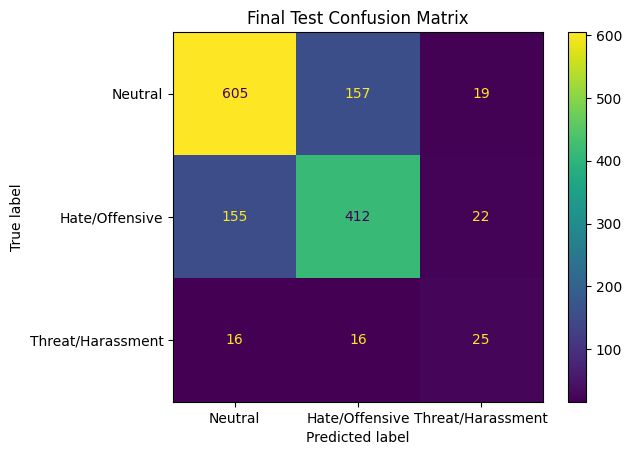

In [59]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_pred,
    labels=[1,2,3],
    display_labels=[
        "Neutral",
        "Hate/Offensive",
        "Threat/Harassment"
    ],
    values_format="d"
)

plt.title("Final Test Confusion Matrix")
plt.show()


# 34. Error Analysis

The goal is to understand model limitations rather than manually change test labels.

Inspect especially:

- Class 3 false negatives;
- Class 3 false positives;
- Neutral vs Hate/Offensive confusion;
- very short comments;
- spelling variants;
- ambiguous/context-dependent comments.


In [60]:
error_df = pd.DataFrame({
    "comment": X_test.values,
    "true_class": y_test.values,
    "predicted_class": final_pred
})

class3_errors = error_df[
    (
        (error_df["true_class"] == 3) |
        (error_df["predicted_class"] == 3)
    ) &
    (
        error_df["true_class"] != error_df["predicted_class"]
    )
].copy()

print("Class 3 related errors:", len(class3_errors))
display(class3_errors.head(30))


Class 3 related errors: 73


,comment,true_class,predicted_class
22,mantri lai gali garne binabau ka ketaketi haru...,2,3
58,aaimai,2,3
63,Laga laga narsangharkariko dhabba itihasma lag...,3,1
109,machiknne mujhi,2,3
157,Tero ta xoraxori xaina kyary,3,1
176,Gyda chapaunu parcha aanuhar pani tystai dukhy...,2,3
189,Motamahila actress huna sakdain,2,3
198,Sharirik apangata bhayeka manisharu desh ko bo...,3,2
230,Yo ta K yesko bau aaya pani belan ko ball Suna...,3,1
268,aarka ko budi bigarne sala,3,2


# 35. Reproducibility Record

Use this section when preparing the methodology chapter.

The preprocessing wording is intentionally precise: **minimal/conservative normalization**, not “no preprocessing”.


In [61]:
reproducibility = {
    "total_final_records": int(len(final_df)),
    "training_samples": int(len(X_train)),
    "test_samples": int(len(X_test)),
    "split": "80/20 stratified",
    "random_state": SEED,
    "test_used_for_model_selection": False,
    "classes": {
        1: "Neutral",
        2: "Hate Speech / Offensive",
        3: "Threatening / Harassment"
    },
    "preprocessing": {
        "method": "Minimal/conservative normalization",
        "unicode_normalization": "NFKC",
        "whitespace_normalization": "collapse whitespace + strip",
        "romanized_words_preserved": True,
        "repeated_characters_preserved": True,
        "meaningful_punctuation_preserved": True,
        "stemming": False,
        "lemmatization": False,
        "aggressive_stopword_removal": False
    },
    "final_classical_model": {
        "vectorizer": "Character TF-IDF",
        "ngram_range": "(3,5)",
        "min_df": 2,
        "sublinear_tf": True,
        "classifier": "Logistic Regression",
        "C": 1,
        "class_weight": "balanced",
        "max_iter": 2000,
        "random_state": SEED
    }
}

for key, value in reproducibility.items():
    print(key, ":", value)


total_final_records : 7133
training_samples : 5706
test_samples : 1427
split : 80/20 stratified
random_state : 42
test_used_for_model_selection : False
classes : {1: 'Neutral', 2: 'Hate Speech / Offensive', 3: 'Threatening / Harassment'}
preprocessing : {'method': 'Minimal/conservative normalization', 'unicode_normalization': 'NFKC', 'whitespace_normalization': 'collapse whitespace + strip', 'romanized_words_preserved': True, 'repeated_characters_preserved': True, 'meaningful_punctuation_preserved': True, 'stemming': False, 'lemmatization': False, 'aggressive_stopword_removal': False}
final_classical_model : {'vectorizer': 'Character TF-IDF', 'ngram_range': '(3,5)', 'min_df': 2, 'sublinear_tf': True, 'classifier': 'Logistic Regression', 'C': 1, 'class_weight': 'balanced', 'max_iter': 2000, 'random_state': 42}


# 36. Completed Classical Model Comparison

These are the previously recorded fixed train/test benchmarks from the project.

**Note:** the Random Forest result from the earlier notebook was not treated as a valid CV estimate because SVD had been fitted before CV. The leakage-safe RF experiment above is the correct version to use.


In [62]:
historical_results = pd.DataFrame([
    [
        "Word TF-IDF + LR",
        0.7148, 0.5796, 0.2764,
        "Rejected"
    ],
    [
        "Character TF-IDF (3-5) + LR",
        0.7379, 0.6379, 0.4202,
        "Current classical benchmark"
    ],
    [
        "Word + Character TF-IDF + LR",
        None, 0.6201, 0.3704,
        "Rejected"
    ],
    [
        "Character TF-IDF + Linear SVM",
        0.7449, 0.5927, 0.2750,
        "Rejected"
    ],
    [
        "Character TF-IDF + MultinomialNB",
        0.6924, 0.4385, 0.0000,
        "Rejected"
    ],
    [
        "Word TF-IDF + Linear SVM",
        0.7183, 0.5657, 0.2366,
        "Rejected"
    ],
    [
        "Character TF-IDF (3-6) + LR",
        0.7428, 0.6344, 0.4000,
        "Rejected vs 3-5"
    ],
    [
        "Tuned Character LR (C=2)",
        0.7442, 0.6247, 0.3670,
        "Rejected vs C=1"
    ]
], columns=[
    "Model",
    "Accuracy",
    "Macro F1",
    "Class 3 F1",
    "Decision"
])

display(historical_results)


,Model,Accuracy,Macro F1,Class 3 F1,Decision
0,Word TF-IDF + LR,0.7148,0.5796,0.2764,Rejected
1,Character TF-IDF (3-5) + LR,0.7379,0.6379,0.4202,Current classical benchmark
2,Word + Character TF-IDF + LR,NaN,0.6201,0.3704,Rejected
3,Character TF-IDF + Linear SVM,0.7449,0.5927,0.2750,Rejected
4,Character TF-IDF + MultinomialNB,0.6924,0.4385,0.0000,Rejected
5,Word TF-IDF + Linear SVM,0.7183,0.5657,0.2366,Rejected
6,Character TF-IDF (3-6) + LR,0.7428,0.6344,0.4000,Rejected vs 3-5
7,Tuned Character LR (C=2),0.7442,0.6247,0.3670,Rejected vs C=1


# ============================================================
# INTERACTIVE COMMENT CLASSIFIER WITH CONFIDENCE
# ============================================================


In [63]:

CLASS_NAMES = {
    1: "Neutral",
    2: "Hate Speech / Offensive",
    3: "Threatening / Harassment"
}

def predict_comment(comment):
    if not isinstance(comment, str) or not comment.strip():
        print("Please enter a valid comment.")
        return

    # Prediction
    predicted_class = FINAL_MODEL.predict([comment])[0]

    # Class probabilities
    probabilities = FINAL_MODEL.predict_proba([comment])[0]
    classes = FINAL_MODEL.classes_

    confidence = probabilities[
        list(classes).index(predicted_class)
    ] * 100

    print("\n" + "=" * 60)
    print("INPUT COMMENT")
    print("=" * 60)
    print(comment)

    print("\nPREDICTION")
    print("=" * 60)
    print(f"Class      : {predicted_class}")
    print(f"Category   : {CLASS_NAMES[predicted_class]}")
    print(f"Confidence : {confidence:.2f}%")

    print("\nALL CLASS PROBABILITIES")
    print("=" * 60)

    for cls, probability in zip(classes, probabilities):
        print(
            f"Class {cls} "
            f"({CLASS_NAMES[cls]}): "
            f"{probability * 100:.2f}%"
        )

    print("=" * 60)


# Interactive loop
while True:
    comment = input(
        "\nEnter a comment "
        "(type 'exit' to stop): "
    )

    if comment.lower().strip() == "exit":
        print("Classifier stopped.")
        break

    predict_comment(comment)


Enter a comment (type 'exit' to stop): i love you

INPUT COMMENT
i love you

PREDICTION
Class      : 2
Category   : Hate Speech / Offensive
Confidence : 52.82%

ALL CLASS PROBABILITIES
Class 1 (Neutral): 40.75%
Class 2 (Hate Speech / Offensive): 52.82%
Class 3 (Threatening / Harassment): 6.42%

Enter a comment (type 'exit' to stop): yo man paryo

INPUT COMMENT
yo man paryo

PREDICTION
Class      : 1
Category   : Neutral
Confidence : 75.16%

ALL CLASS PROBABILITIES
Class 1 (Neutral): 75.16%
Class 2 (Hate Speech / Offensive): 14.86%
Class 3 (Threatening / Harassment): 9.98%

Enter a comment (type 'exit' to stop): i love it 

INPUT COMMENT
i love it 

PREDICTION
Class      : 2
Category   : Hate Speech / Offensive
Confidence : 52.01%

ALL CLASS PROBABILITIES
Class 1 (Neutral): 41.60%
Class 2 (Hate Speech / Offensive): 52.01%
Class 3 (Threatening / Harassment): 6.39%

Enter a comment (type 'exit' to stop): man paryo

INPUT COMMENT
man paryo

PREDICTION
Class      : 1
Category   : Neutral
C